# TD07 — Évaluer un modèle, courbes d'apprentissage et élan

## Objectif

Ce TD prolonge le TD03 (MLP et rétropropagation) et le chapitre « 6 - Évaluer un modèle ». On y **mesure** la qualité d'un modèle au lieu de la supposer : matrice de confusion et métriques adaptées aux classes déséquilibrées, puis courbes d'apprentissage sur un jeu d'entraînement et un jeu de test.

On étudie ensuite l'**élan** (momentum) : son effet sur la vitesse d'apprentissage et sur le surapprentissage, lu sur les courbes d'apprentissage. Le réglage des hyper-paramètres (protocole entraînement / validation / test) est abordé en bonus.

Les données sont générées par des fonctions fournies (blobs déséquilibrés, lunes, spirales) ; le MLP fourni est un perceptron multicouche à activations tanh (couches cachées) et sigmoïde (sortie).

## Préambule

Les cellules ci-dessous sont fournies : alias de types, générateurs de données, classe `MLP` (même structure qu'au TD03, activations figées) et fonctions de tracé.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Alias de types pour les tableaux numpy
Vec = np.ndarray[tuple[int], np.dtype[np.float64]]        # vecteur 1D de flottants
Mat = np.ndarray[tuple[int, int], np.dtype[np.float64]]   # matrice 2D de flottants

### Générateurs de données

Chaque générateur renvoie `X` de forme $(n, 2)$ et les cibles `t` de forme $(n, 1)$, en flottants `0.` / `1.`. L'argument `seed` fixe le tirage. `split` mélange un jeu et le découpe en entraînement, test, et un reste mis de côté.

In [2]:
def make_blobs_imbalanced(n: int, noise: float = 0.6, pos_frac: float = 0.1, seed: int = 1) -> tuple[Mat, Mat]:
    """Deux nuages gaussiens, classe 1 minoritaire.

    Classe 0 centrée en (0, 0), classe 1 centrée en (1, 1) ; chaque point est
    de classe 1 avec la probabilité `pos_frac`.

    Returns
    -------
    tuple[Mat, Mat]
        X de forme (n, 2) et t de forme (n, 1).
    """
    rng = np.random.default_rng(seed)
    lab = (rng.uniform(size=n) < pos_frac).astype(float)
    centers = np.where(lab[:, None] == 1, [1.0, 1.0], [0.0, 0.0])
    X = centers + rng.normal(0.0, noise, size=(n, 2))
    return X, lab[:, None]


def make_moons(n: int, noise: float = 0.3, seed: int = 1) -> tuple[Mat, Mat]:
    """Deux demi-lunes entrelacées, bruit gaussien d'écart-type `noise`.

    Returns
    -------
    tuple[Mat, Mat]
        X de forme (n, 2) et t de forme (n, 1).
    """
    rng = np.random.default_rng(seed)
    a = rng.uniform(0.0, np.pi, size=n)
    lab = rng.integers(0, 2, size=n)
    x = np.where(lab == 0, np.cos(a), 1.0 - np.cos(a))
    y = np.where(lab == 0, np.sin(a), 0.5 - np.sin(a))
    X = np.c_[x, y] + rng.normal(0.0, noise, size=(n, 2))
    return X, lab[:, None].astype(float)


def make_spirals(n: int, noise: float = 0.08, seed: int = 1) -> tuple[Mat, Mat]:
    """Deux spirales entrelacées (rayon r dans [0.2, 1], angle 3πr, +π pour la classe 1).

    Returns
    -------
    tuple[Mat, Mat]
        X de forme (n, 2) et t de forme (n, 1).
    """
    rng = np.random.default_rng(seed)
    lab = rng.integers(0, 2, size=n)
    r = rng.uniform(0.2, 1.0, size=n)
    theta = 3 * np.pi * r + lab * np.pi
    X = np.c_[r * np.cos(theta), r * np.sin(theta)] + rng.normal(0.0, noise, size=(n, 2))
    return X, lab[:, None].astype(float)


def split(X: Mat, t: Mat, n_train: int, n_test: int, seed: int = 0) -> tuple[Mat, Mat, Mat, Mat, Mat, Mat]:
    """Mélange les exemples puis renvoie X_tr, t_tr, X_te, t_te, X_rest, t_rest.

    Les `n_train` premiers exemples pour l'entraînement, les `n_test`
    suivants pour le test, le reste est mis de côté.
    """
    perm = np.random.default_rng(seed).permutation(len(X))
    X, t = X[perm], t[perm]
    a, b = n_train, n_train + n_test
    return X[:a], t[:a], X[a:b], t[a:b], X[b:], t[b:]

### Le réseau

`MLP(sizes, seed)` : couches cachées en tanh, sortie sigmoïde, poids initialisés selon $\mathcal N(0, 0.5)$, biais nuls. Le coût est celui du cours, $E = \tfrac12\,\operatorname{mean}\sum_k (Y_k - T_k)^2$, et `error_rate` donne la proportion d'exemples mal classés au seuil choisi.

`fit` effectue une étape de descente de gradient par époque (sur tout le jeu) et enregistre l'historique **après** chaque étape : l'entrée `i` de l'historique correspond à l'état du modèle après `i + 1` étapes. Si un jeu de test est fourni (`X_test`, `t_test`), le coût et le taux d'erreur sur ce jeu sont aussi enregistrés, sous les clés `"test"` et `"err_test"` (listes vides sinon). Le test ne sert qu'à **mesurer** : il ne modifie jamais les poids.

In [3]:
class MLP:
    def __init__(self, sizes: list[int], seed: int = 0):
        rng = np.random.default_rng(seed)
        self.sizes = list(sizes)
        self.Ws: list[Mat] = []
        self.bs: list[Vec] = []
        for n_in, n_out in zip(sizes[:-1], sizes[1:]):
            self.Ws.append(rng.normal(0.0, 0.5, size=(n_out, n_in)))
            self.bs.append(np.zeros(n_out))

    def forward(self, X: Mat) -> tuple[list[Mat], list[Mat]]:
        """Passe avant : renvoie (As, Zs), activations (avec Y0 = X en tête) et pré-activations."""
        A = X
        As = [A]
        Zs = []
        n = len(self.Ws)
        for l, (W, b) in enumerate(zip(self.Ws, self.bs)):
            Z = A @ W.T + b
            Zs.append(Z)
            A = 1.0 / (1.0 + np.exp(-Z)) if l == n - 1 else np.tanh(Z)
            As.append(A)
        return As, Zs

    def backward(self, X: Mat, t: Mat) -> list[tuple[Mat, Vec]]:
        """Passe arrière : liste de (dW_l, db_l), une paire par couche."""
        As, Zs = self.forward(X)
        N = X.shape[0]
        Y = As[-1]
        delta = (Y - t) * Y * (1.0 - Y)
        grads: list[tuple[Mat, Vec]] = []
        for l in reversed(range(len(self.Ws))):
            dW = delta.T @ As[l] / N
            db = delta.mean(axis=0)
            grads.append((dW, db))
            if l > 0:
                delta = (delta @ self.Ws[l]) * (1.0 - np.tanh(Zs[l - 1]) ** 2)
        grads.reverse()
        return grads

    def step(self, X: Mat, t: Mat, lr: float) -> None:
        """Une étape de descente de gradient sur le jeu (X, t)."""
        for l, (dW, db) in enumerate(self.backward(X, t)):
            self.Ws[l] = self.Ws[l] - lr * dW
            self.bs[l] = self.bs[l] - lr * db

    def predict(self, X: Mat) -> Mat:
        """Probabilités de la classe 1, de forme (N, 1)."""
        return self.forward(X)[0][-1]

    def loss(self, X: Mat, t: Mat) -> float:
        """Coût : E = (1/2) · mean(Σ_k (Y_k - T_k)²)."""
        return 0.5 * float(np.mean(np.sum((self.predict(X) - t) ** 2, axis=1)))

    def error_rate(self, X: Mat, t: Mat, threshold: float = 0.5) -> float:
        """Proportion d'exemples mal classés (classe 1 prédite si la probabilité est supérieure ou égale à `threshold`)."""
        return float(np.mean((self.predict(X) >= threshold) != (t > 0.5)))

    def fit(self, X: Mat, t: Mat, lr: float, epochs: int,
            X_test: Mat | None = None, t_test: Mat | None = None) -> dict[str, list[float]]:
        """Entraîne le réseau (une étape par époque) et renvoie l'historique.

        Clés : `"train"`, `"test"` (coûts) et `"err_train"`, `"err_test"`
        (taux d'erreur). L'entrée i est mesurée après i + 1 étapes ; les listes
        `"test"` et `"err_test"` restent vides sans jeu de test.
        """
        history: dict[str, list[float]] = {"train": [], "test": [], "err_train": [], "err_test": []}
        has_test = X_test is not None and t_test is not None
        for _ in range(epochs):
            self.step(X, t, lr)
            history["train"].append(self.loss(X, t))
            history["err_train"].append(self.error_rate(X, t))
            if has_test:
                history["test"].append(self.loss(X_test, t_test))
                history["err_test"].append(self.error_rate(X_test, t_test))
        return history

### Tracés

`plot_curves` superpose les courbes d'apprentissage de plusieurs entraînements (une couleur par entrée ; train en pointillés, test en trait plein). Avec `metric="err"`, on trace les taux d'erreur au lieu du coût. `plot_data` affiche un nuage de points coloré par classe (classe 0 en rouge, classe 1 en bleu), `plot_decision` ajoute la frontière de décision d'un modèle (probabilité 0.5).

In [4]:
def plot_curves(histories: dict[str, dict[str, list[float]]], metric: str = "loss",
                logx: bool = True, ax=None):
    """Courbes d'apprentissage de plusieurs historiques sur un même graphique.

    `metric="loss"` trace le coût, `metric="err"` les taux d'erreur.
    """
    if ax is None:
        fig, ax = plt.subplots()
    k_tr, k_va = ("train", "test") if metric == "loss" else ("err_train", "err_test")
    for i, (name, h) in enumerate(histories.items()):
        c = f"C{i}"
        x = np.arange(1, len(h[k_tr]) + 1)
        ax.plot(x, h[k_tr], color=c, ls="--", lw=1)
        if h[k_va]:
            ax.plot(x, h[k_va], color=c, label=name)
        else:
            ax.plot([], [], color=c, ls="--", label=name)
    ax.set_xlabel("époque")
    ax.set_ylabel("coût" if metric == "loss" else "taux d'erreur")
    if logx:
        ax.set_xscale("log")
    if metric == "loss":
        ax.set_yscale("log")
    ax.legend()
    ax.grid(True)
    return ax


def plot_data(X: Mat, t: Mat, ax=None):
    """Nuage de points coloré par classe (classe 0 en rouge, classe 1 en bleu), avec légende."""
    if ax is None:
        fig, ax = plt.subplots()
    for k, color in ((0, "tab:red"), (1, "tab:blue")):
        mask = t.ravel() == k
        ax.scatter(X[mask, 0], X[mask, 1], color=color, label=f"classe {k}",
                   edgecolors="w", linewidths=0.5, s=25, zorder=3)
    ax.legend(loc="upper left")
    ax.set_aspect("equal")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.grid(True)
    return ax


def plot_decision(model: MLP, X: Mat, t: Mat, ax=None):
    """Probabilité prédite (fond), frontière à 0.5 (trait noir) et points (X, t)."""
    if ax is None:
        fig, ax = plt.subplots()
    m = 0.3
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - m, X[:, 0].max() + m, 200),
                         np.linspace(X[:, 1].min() - m, X[:, 1].max() + m, 200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.linspace(0, 1, 21), cmap="RdBu", alpha=0.6)
    ax.contour(xx, yy, Z, levels=[0.5], colors="k", linewidths=2)
    plot_data(X, t, ax=ax)
    return ax

## 1. Évaluer un classifieur : la matrice de confusion

Pour un classifieur binaire, la classe **positive** (1) est la classe d'intérêt (la fraude, la maladie, l'intrusion…) ; la sortie sigmoïde est seuillée à 0.5. Dans ce TD, $y$ désigne la prédiction 0/1 obtenue en seuillant la sortie sigmoïde $Y$ (la probabilité de la classe 1). Comparer les prédictions $y$ aux cibles $t$ donne quatre comptes, rangés dans la **matrice de confusion** :

| | prédit positif ($y = 1$) | prédit négatif ($y = 0$) |
|---|---|---|
| **réel positif** ($t = 1$) | TP (vrais positifs) | FN (faux négatifs) |
| **réel négatif** ($t = 0$) | FP (faux positifs) | TN (vrais négatifs) |

À partir de ces comptes, avec $N = \mathrm{TP} + \mathrm{FP} + \mathrm{TN} + \mathrm{FN}$ :

- **accuracy** (taux de bonne classification) : $\dfrac{\mathrm{TP} + \mathrm{TN}}{N}$ ;
- **précision** : $\dfrac{\mathrm{TP}}{\mathrm{TP} + \mathrm{FP}}$, parmi les exemples prédits positifs, la part qui l'est vraiment ;
- **rappel** : $\dfrac{\mathrm{TP}}{\mathrm{TP} + \mathrm{FN}}$, parmi les vrais positifs, la part détectée.

Par convention, la précision vaut 0 lorsqu'aucun exemple n'est prédit positif ($\mathrm{TP} + \mathrm{FP} = 0$), et le rappel vaut 0 lorsqu'il n'y a aucun positif réel.

### 1.1 Les données

On utilise deux nuages gaussiens dont la classe 1 est minoritaire (chaque point est positif avec une probabilité de 0.1) : un petit jeu d'entraînement (100 points) et un grand jeu de test (1000 points), tirés avec des graines différentes. La cellule suivante les génère et les affiche.

train : 100 points, 8 positifs
test  : 1000 points, 80 positifs (8.0%)


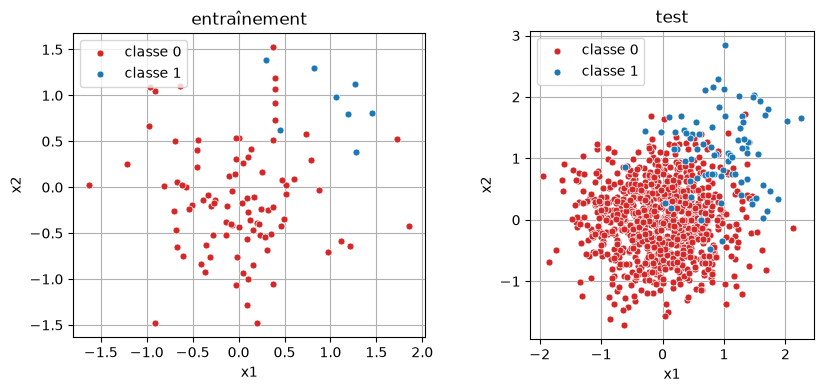

In [5]:
Xb_tr, tb_tr = make_blobs_imbalanced(100, seed=1)
Xb_te, tb_te = make_blobs_imbalanced(1000, seed=2)
print(f"train : {len(tb_tr)} points, {int(tb_tr.sum())} positifs")
print(f"test  : {len(tb_te)} points, {int(tb_te.sum())} positifs ({tb_te.mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
plot_data(Xb_tr, tb_tr, ax=axes[0]); axes[0].set_title("entraînement")
plot_data(Xb_te, tb_te, ax=axes[1]); axes[1].set_title("test")
plt.show()

### 1.2 Matrice de confusion

La fonction `classify`, fournie, transforme les sorties `Y` du réseau (probabilités) en prédictions 0./1. de forme `(N,)` : la classe 1 est prédite si la probabilité est supérieure **ou égale** à `threshold` (0.5 par défaut).

In [6]:
def classify(Y: Mat, threshold: float = 0.5) -> Vec:
    """Prédictions 0/1 à partir des probabilités de la classe 1.

    `Y` est la sortie du réseau, de forme (N, 1) (une colonne, une ligne par
    exemple). Renvoie un vecteur de forme (N,) : 1. si la probabilité est
    supérieure ou égale à `threshold`, 0. sinon. `Y.ravel()` aplatit
    (N, 1) en (N,).
    """
    return (Y.ravel() >= threshold).astype(float)


> **Exercice 1** — Complétez `confusion`, qui renvoie le tuple `(TP, FP, TN, FN)` ; `t` et `y` sont des étiquettes 0/1 de forme `(N,)` ou `(N, 1)`.

In [9]:
def confusion(t: Vec | Mat, y: Vec | Mat) -> tuple[int, int, int, int]:
    """Comptes (TP, FP, TN, FN) de la matrice de confusion.

    `t` (cibles) et `y` (prédictions) contiennent des 0. / 1. et peuvent
    être de forme (N, 1), comme les cibles renvoyées par les générateurs, ou
    (N,), comme la sortie de `classify`. Les aplatir d'abord en (N,) avec
    `.ravel()` : comparer directement un (N, 1) à un (N,) diffuserait en une
    matrice (N, N) et fausserait les comptes.
    """
    # TODO
    t = t.ravel()
    y = y.ravel()
    tp = int(np.sum((t == 1) & (y == 1)))
    fp = int(np.sum((t == 0) & (y == 1)))
    tn = int(np.sum((t == 0) & (y == 0)))
    fn = int(np.sum((t == 1) & (y == 0)))
    return tp, fp, tn, fn    # Indice : aplatir t et y, puis compter avec des masques booléens (t == 1) & (y == 1), etc.


In [10]:
def check_confusion():
    t = np.array([1, 1, 1, 0, 0, 0, 0, 0.])
    y = np.array([1, 0, 0, 1, 0, 0, 0, 0.])
    assert confusion(t, y) == (1, 1, 4, 2), "confusion incorrecte"
    assert confusion(t.reshape(-1, 1), y) == (1, 1, 4, 2), "confusion incorrecte avec t de forme (N, 1)"
    print("confusion check — OK")

check_confusion()

confusion check — OK


### 1.3 Accuracy, précision, rappel

> **Exercice 2** — Complétez `accuracy`, `precision` et `recall` en vous appuyant sur `confusion`. Si le dénominateur est nul, `precision` et `recall` renvoient `0.0` (sans division par zéro ni avertissement).

In [11]:
def accuracy(t: Vec | Mat, y: Vec | Mat) -> float:
    # BEGIN
    # raise NotImplementedError
    tp, fp, tn, fn = confusion(t, y)
    return (tp + tn) / (tp + fp + tn + fn)
    # END


def precision(t: Vec | Mat, y: Vec | Mat) -> float:
    # BEGIN
    # raise NotImplementedError
    tp, fp, tn, fn = confusion(t, y)
    return tp / (tp + fp) if tp + fp > 0 else 0.0
    # END


def recall(t: Vec | Mat, y: Vec | Mat) -> float:
    # BEGIN
    # raise NotImplementedError
    tp, fp, tn, fn = confusion(t, y)
    return tp / (tp + fn) if tp + fn > 0 else 0.0
    # END

In [12]:
import warnings

def check_metrics():
    t = np.array([1, 1, 1, 0, 0, 0, 0, 0.])
    y = np.array([1, 0, 0, 1, 0, 0, 0, 0.])
    y0 = np.zeros(8)
    with warnings.catch_warnings():
        warnings.simplefilter("error")
        assert accuracy(t, y) == 5 / 8, "accuracy incorrecte"
        assert precision(t, y) == 0.5, "precision incorrecte"
        assert recall(t, y) == 1 / 3, "recall incorrect"
        assert precision(t, y0) == 0.0, "precision doit valoir 0 si aucun positif prédit"
        assert recall(t, y0) == 0.0, "recall incorrect pour le classifieur toujours négatif"
        assert accuracy(t, y0) == 5 / 8, "accuracy incorrecte pour le classifieur toujours négatif"
    print("metrics check — OK")

check_metrics()

metrics check — OK


### 1.4 Le piège de l'accuracy

Pour comparer plusieurs classifieurs, on regroupe d'abord la matrice de confusion et les trois métriques dans un seul dictionnaire.

> **Exercice 3** — Complétez `evaluate` en vous appuyant sur `confusion` et sur les fonctions de l'exercice 2. Le format du dictionnaire renvoyé est donné dans la docstring. La fonction `show`, fournie, l'affiche sur une ligne.

In [15]:
def evaluate(t: Vec | Mat, y: Vec | Mat) -> dict[str, float]:
    """Matrice de confusion et métriques des prédictions `y` par rapport aux cibles `t`.

    `t` et `y` sont de forme (N,) ou (N, 1), comme pour `confusion`. Renvoie un
    dictionnaire à sept clés :

    - "TP", "FP", "TN", "FN" : les quatre comptes de `confusion` (entiers) ;
    - "accuracy", "precision", "recall" : les trois métriques (flottants).
    """
    # BEGIN
    # raise NotImplementedError
    tp, fp, tn, fn = confusion(t, y)
    return {"TP": tp, "FP": fp, "TN": tn, "FN": fn,
            "accuracy": accuracy(t, y),
            "precision": precision(t, y),
            "recall": recall(t, y)}
    # END


def show(name: str, res: dict[str, float]) -> None:
    counts = "  ".join(f"{k}={int(res[k])}" for k in ("TP", "FP", "TN", "FN"))
    print(f"{name:18s} {counts}  | accuracy={res['accuracy']:.3f}  "
          f"précision={res['precision']:.3f}  rappel={res['recall']:.3f}")

In [16]:
def check_evaluate():
    t = np.array([1, 1, 1, 0, 0, 0, 0, 0.])
    y = np.array([1, 0, 0, 1, 0, 0, 0, 0.])
    res = evaluate(t, y)
    assert (res["TP"], res["FP"], res["TN"], res["FN"]) == (1, 1, 4, 2), "comptes incorrects"
    assert res["accuracy"] == 5 / 8 and res["precision"] == 0.5 and res["recall"] == 1 / 3, "métriques incorrectes"
    print("evaluate check — OK")

check_evaluate()

evaluate check — OK


On peut maintenant mesurer le piège annoncé dans le cours : sur des classes déséquilibrées, un classifieur qui ne détecte rien peut avoir une très bonne accuracy.

> **Exercice 4** — On compare, **sur le jeu de test**, deux classifieurs :
>
> 1. **le classifieur « toujours négatif »** : il n'apprend rien et répond « classe 0 » pour chaque point, quel qu'il soit. C'est la référence la plus bête possible ; un vrai modèle doit faire mieux que lui.
> 2. **un MLP entraîné** : un réseau `MLP([2, 16, 1], seed=0)`, nommé `model`, entraîné **uniquement sur le jeu d'entraînement** (100 points) avec `fit`, un pas `lr=1.0` et `epochs=2000`. Une fois entraîné, on lui fait prédire les probabilités des points **de test**, que `classify` transforme en prédictions 0./1.
>
> Pour chacun, construisez le vecteur de ses prédictions sur le jeu de test : une valeur 0. ou 1. par point de test, de forme `(N,)` avec `N = 1000`. Nommez-les `y_zero` et `y_mlp`. La cellule affiche ensuite, avec `evaluate` et `show`, la matrice de confusion et les métriques de chacun par rapport aux cibles du test `tb_te`.
>
> Comparez les deux lignes : lequel a la meilleure accuracy, et de combien ? Lequel détecte des positifs ?

In [17]:
# BEGIN
## Rappel: Xb_tr:  données de train,  tb_tr: target de train
# y_zero = ... 
# model = ...
# ...
# y_mlp = ...
y_zero = np.zeros(len(tb_te))
model = MLP([2, 16, 1], seed=0)
model.fit(Xb_tr, tb_tr, lr=1.0, epochs=2000)
y_mlp = classify(model.predict(Xb_te))
# END

show("toujours négatif", evaluate(tb_te, y_zero))
show("MLP [2, 16, 1]", evaluate(tb_te, y_mlp))

toujours négatif   TP=0  FP=0  TN=920  FN=80  | accuracy=0.920  précision=0.000  rappel=0.000
MLP [2, 16, 1]     TP=46  FP=18  TN=902  FN=34  | accuracy=0.948  précision=0.719  rappel=0.575


In [18]:
def check_predictions():
    assert y_zero.shape == (len(tb_te),) and not y_zero.any(), "y_zero doit être le vecteur nul de forme (N,)"
    assert y_mlp.shape == (len(tb_te),), "y_mlp doit avoir la forme (N,)"
    assert set(np.unique(y_mlp)) <= {0.0, 1.0}, "y_mlp doit contenir des prédictions 0./1."
    print("prédictions check — OK")

check_predictions()

prédictions check — OK


#### Lecture des résultats

Le classifieur « toujours négatif » ne détecte aucun des 80 positifs du test (rappel nul, précision nulle par convention), et pourtant son accuracy vaut 0.920 : les négatifs représentent 92 % des exemples. Le MLP atteint 0.948, soit seulement 2,8 points de plus, alors qu'il détecte 46 positifs sur 80 (rappel 0.575, précision 0.719).

Sur des classes déséquilibrées, l'accuracy ne distingue donc pas un classifieur inutile d'un classifieur utile ; ce sont la précision et le rappel, lus avec la matrice de confusion, qui renseignent sur la classe minoritaire.

### 1.5 Le seuil : précision contre rappel

La sortie du MLP est une probabilité ; le seuil de décision est un réglage, pas une fatalité. Baisser le seuil prédit plus d'exemples positifs, l'élever en prédit moins.

> **Exercice 5** — Complétez `sweep_threshold`, qui renvoie la précision et le rappel obtenus sur `(X, t)` pour chaque seuil de `thresholds`. On trace ensuite les deux courbes en fonction du seuil, pour le MLP entraîné à l'exercice 4.

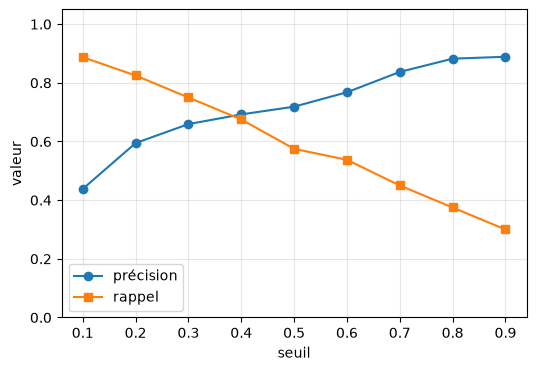

In [19]:
def sweep_threshold(model: MLP, X: Mat, t: Mat, thresholds: Vec) -> tuple[Vec, Vec]:
    """Précision et rappel du modèle sur `(X, t)`, pour chaque seuil de décision.

    - `X` est le vecteur d'entrée (de forme (N, 2))
    - `t` (cibles 0./1.) de forme (N, 1)
    - `thresholds` est un vecteur de K seuils entre 0 et 1. 

    Renvoie deux vecteurs de forme (K,) : `precs[k]` et `recs[k]` sont la
    précision et le rappel obtenus avec le seuil `thresholds[k]`.
    """
    # BEGIN
    # raise NotImplementedError
    ## Indice : utiliser la fonction classify
    Y = model.predict(X)
    precs = np.array([precision(t, classify(Y, s)) for s in thresholds])
    recs = np.array([recall(t, classify(Y, s)) for s in thresholds])
    return precs, recs
    # END


thresholds = np.linspace(0.1, 0.9, 9)
precs, recs = sweep_threshold(model, Xb_te, tb_te, thresholds)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(thresholds, precs, "o-", label="précision")
ax.plot(thresholds, recs, "s-", label="rappel")
ax.set_xlabel("seuil"); ax.set_ylabel("valeur"); ax.set_ylim(0, 1.05)
ax.legend(); ax.grid(alpha=0.3)
plt.show()

In [20]:
def check_sweep():
    class Fixe:
        def predict(self, X):
            return np.array([[0.9], [0.6], [0.4], [0.2], [0.1]])
    t = np.array([[1.], [0.], [1.], [0.], [0.]])
    precs, recs = sweep_threshold(Fixe(), None, t, np.array([0.3, 0.5, 0.95]))
    # seuil 0.3 : y = [1, 1, 1, 0, 0] -> TP=2, FP=1, FN=0 ; seuil 0.5 : y = [1, 1, 0, 0, 0] -> TP=1, FP=1, FN=1
    # seuil 0.95 : y = 0 partout -> précision 0 (convention), rappel 0
    assert np.array_equal(precs, np.array([2 / 3, 0.5, 0.0])), "précisions incorrectes"
    assert np.array_equal(recs, np.array([1.0, 0.5, 0.0])), "rappels incorrects"
    print("sweep check — OK")

check_sweep()

sweep check — OK


> **Question** — Pour un détecteur de fraude bancaire (la fraude est la classe positive), faut-il privilégier la précision ou le rappel ? Quel seuil serait-on tenté de choisir, et quel prix paie-t-on ?

*Votre réponse :*

## 2. Courbes d'apprentissage

Un réseau est jugé sur des données qu'il n'a **pas** vues pendant l'entraînement (le *hold-out* du chapitre 1). On découpe donc les données en deux jeux :

- **entraînement** (train) : sert à calculer les gradients et à modifier les poids ;
- **test** : sert seulement à **mesurer** l'erreur sur des données nouvelles ; le réseau ne s'entraîne jamais dessus.

Une **courbe d'apprentissage** trace l'erreur en fonction des époques, pour l'entraînement **et** pour le test, sur le même graphe.

### 2.1 Entraîner et tracer les courbes

On travaille sur le jeu des deux lunes (bruit gaussien 0.3). Le jeu d'entraînement est volontairement **petit** (60 points) pour que le réseau, bien plus grand qu'il n'en faut (deux couches cachées de 32 neurones), puisse apprendre le bruit par cœur. Le test (500 points) est plus grand, donc plus fiable. Les 500 points restants sont mis de côté pour le bonus : on ne s'en sert pas d'ici là.

La cellule suivante entraîne le réseau **sans élan** par descente de gradient sur le lot complet, en mesurant à chaque époque le coût et le taux d'erreur sur le jeu d'entraînement et sur le jeu de test. L'historique est rangé dans `hist_plain`. On affiche ensuite les courbes (axe des époques en échelle logarithmique : tirets pour l'entraînement, trait plein pour le test), puis la frontière de décision finale.

train : 60 points, test : 500 points (+ 500 mis de côté pour le bonus)


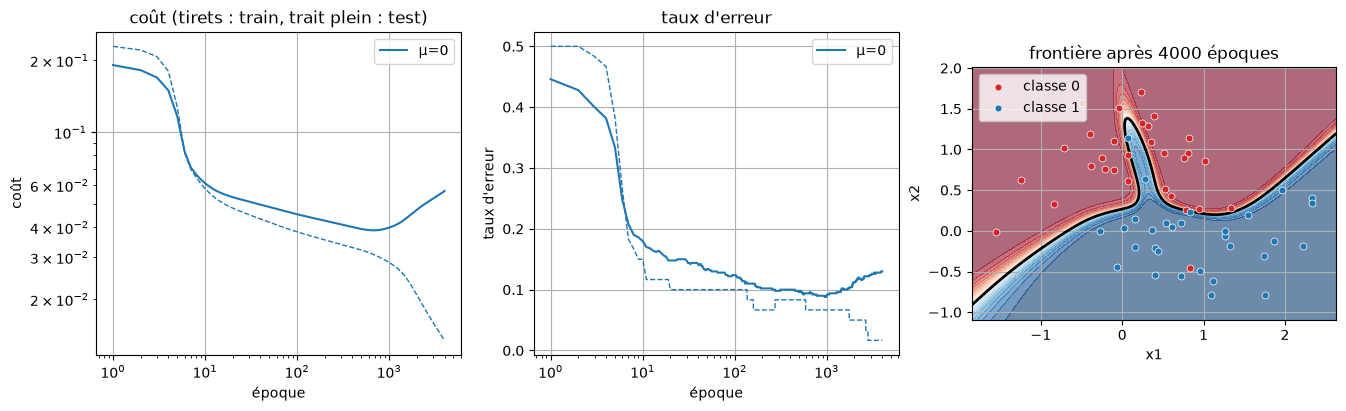

In [21]:
SIZES = [2, 32, 32, 1]
LR = 0.5
EPOCHS = 4000

X, t = make_moons(1060, noise=0.3, seed=1)
X_tr, t_tr, X_te, t_te, X_new, t_new = split(X, t, n_train=60, n_test=500)
print(f"train : {len(t_tr)} points, test : {len(t_te)} points (+ {len(t_new)} mis de côté pour le bonus)")

model_plain = MLP(SIZES, seed=0)
hist_plain = model_plain.fit(X_tr, t_tr, lr=LR, epochs=EPOCHS, X_test=X_te, t_test=t_te)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
plot_curves({"μ=0": hist_plain}, metric="loss", ax=axes[0])
axes[0].set_title("coût (tirets : train, trait plein : test)")
plot_curves({"μ=0": hist_plain}, metric="err", ax=axes[1])
axes[1].set_title("taux d'erreur")
plot_decision(model_plain, X_tr, t_tr, ax=axes[2])
axes[2].set_title(f"frontière après {EPOCHS} époques")
plt.show()

### 2.2 Lire les courbes

Une courbe d'apprentissage prend l'un des profils suivants :

- **sous-apprentissage** : coûts d'entraînement et de test tous deux élevés, le réseau n'a pas encore appris ;
- **bon régime** : les deux coûts baissent ensemble, avec un écart faible entre eux ;
- **surapprentissage** : le coût d'entraînement continue de baisser mais celui de test **remonte**, l'écart se creuse ;
- **instabilité** : des oscillations ou une divergence (pas d'apprentissage trop grand, ou, on le verra, élan trop grand).

> **Exercice 6** — Complétez la cellule ci-dessous : `best_idx` est l'indice, dans `hist_plain["test"]`, du minimum du coût de test (l'entrée d'indice $i$ a été mesurée après $i + 1$ étapes), et `best_test` est la valeur de ce minimum. La cellule affiche ensuite quelques valeurs à lire.

In [ ]:
# TODO
# Rappel : hist_plain["test"] est la liste des coûts de test, un par époque.
# Indice : np.argmin donne l'indice du minimum.
best_idx = ...
best_test = ...
print(f"minimum du coût de test : {best_test:.4f} à l'indice {best_idx} (après {best_idx + 1} étapes)")
print(f"coût d'entraînement à ce moment : {hist_plain['train'][best_idx]:.4f}")
print(f"taux d'erreur de test à ce moment : {hist_plain['err_test'][best_idx]:.3f}")
best_idx_err = int(np.argmin(hist_plain["err_test"]))
print(f"minimum du taux d'erreur de test : {hist_plain['err_test'][best_idx_err]:.3f} à l'indice {best_idx_err}")
print(f"fin d'entraînement : coût train {hist_plain['train'][-1]:.4f}, coût test {hist_plain['test'][-1]:.4f}, "
      f"erreur train {hist_plain['err_train'][-1]:.3f}, erreur test {hist_plain['err_test'][-1]:.3f}")

In [ ]:
def check_best_idx():
    assert isinstance(best_idx, (int, np.integer)), "best_idx doit être un entier (indice dans hist_plain[\"val\"])"
    assert isinstance(best_test, (float, np.floating)), "best_test doit être un nombre"
    assert 0 <= best_idx < EPOCHS, "best_idx doit être un indice d'époque valide"
    assert best_test == min(hist_plain["test"]), "best_test n'est pas le minimum du coût de test"
    assert hist_plain["test"][best_idx] == best_test, "best_idx ne pointe pas sur le minimum"
    print("lecture du minimum — OK")

check_best_idx()

> **Question 6** — À l'aide des courbes et des valeurs affichées :
> 1. Où se situe le sous-apprentissage (quelles époques, quelles valeurs de coût) ?
> 2. Où commence le surapprentissage, et que fait le coût d'entraînement pendant ce temps ?
> 3. Le coût de test et le taux d'erreur de test racontent-ils exactement la même chose ? Comparez l'époque de leur minimum.

*Votre réponse :*

## 3. L'élan à travers les courbes

### 3.1 La règle d'élan

À chaque étape, la descente de gradient simple déplace les poids de $-\eta\,\partial E/\partial W$. L'**élan** (momentum) ajoute une *vitesse* $v$ qui garde la mémoire des étapes précédentes :

$$v \leftarrow \mu\, v + \eta\,\frac{\partial E}{\partial W}, \qquad W \leftarrow W - v$$

(et de même pour les biais). L'image est celle d'une bille qui roule dans le paysage du coût : elle prend de la vitesse tant que la pente garde le même sens, et un coefficient $\mu$ proche de 1 lui fait garder longtemps son élan. Avec $\mu = 0$, on retrouve exactement la descente de gradient simple.

On compare ici, **dans des conditions identiques** (mêmes données, même initialisation, même $\eta$, même nombre d'époques), l'entraînement sans élan ($\mu = 0$, déjà fait dans `hist_plain`) et avec $\mu = 0.9$ et $\mu = 0.99$. Seul $\mu$ change.

> **Exercice 7** — Complétez la méthode `step` de `MLPMomentum` : pour chaque couche, mettre à jour les vitesses `vWs[l]` et `vbs[l]` d'après les gradients renvoyés par `self.backward`, puis retirer la vitesse aux poids et aux biais. Le constructeur est fourni : il crée les vitesses (nulles, de mêmes formes que `Ws` et `bs`).

In [ ]:
class MLPMomentum(MLP):
    def __init__(self, sizes: list[int], seed: int = 0, momentum: float = 0.9):
        super().__init__(sizes, seed)
        self.momentum = momentum
        self.vWs: list[Mat] = [np.zeros_like(W) for W in self.Ws]
        self.vbs: list[Vec] = [np.zeros_like(b) for b in self.bs]

    def step(self, X: Mat, t: Mat, lr: float) -> None:
        """Une étape de descente de gradient avec élan sur le jeu (X, t)."""
        # TODO
        raise NotImplementedError
        # Indice : v <- momentum * v + lr * gradient, puis W <- W - v (idem pour les biais).


In [ ]:
def check_momentum():
    Xc = np.random.default_rng(0).normal(size=(5, 2))
    tc = (np.random.default_rng(1).uniform(size=(5, 1)) > 0.5).astype(float)

    # élan nul : même trajectoire que le MLP sans élan
    plain = MLP([2, 3, 1], seed=1)
    plain.fit(Xc, tc, lr=0.5, epochs=3)
    zero = MLPMomentum([2, 3, 1], seed=1, momentum=0.0)
    zero.fit(Xc, tc, lr=0.5, epochs=3)
    for l in range(len(plain.Ws)):
        assert np.allclose(zero.Ws[l], plain.Ws[l], atol=1e-12), f"avec momentum=0, Ws[{l}] diffère du MLP sans élan"
        assert np.allclose(zero.bs[l], plain.bs[l], atol=1e-12), f"avec momentum=0, bs[{l}] diffère du MLP sans élan"

    # élan 0.9, deux étapes : poids de référence
    ref_W = [np.array([[0.14673871803484698, 0.39851181588559315],
                       [0.19515453685032108, -0.6368897938974577],
                       [0.46981739983849297, 0.23128706456123407]]),
             np.array([[-0.22303683110313538, 0.267899150610648, 0.24655544403224489]])]
    ref_b = [np.array([-0.00955612603057793, 0.01376131709714779, 0.00525673780723384]),
             np.array([0.03565953506558011])]
    mom = MLPMomentum([2, 3, 1], seed=1, momentum=0.9)
    mom.fit(Xc, tc, lr=0.5, epochs=2)
    sans = MLP([2, 3, 1], seed=1)
    sans.fit(Xc, tc, lr=0.5, epochs=2)
    for l in range(len(ref_W)):
        assert np.allclose(mom.Ws[l], ref_W[l], atol=1e-8), f"Ws[{l}] incorrect après 2 étapes avec élan 0.9"
        assert np.allclose(mom.bs[l], ref_b[l], atol=1e-8), f"bs[{l}] incorrect après 2 étapes avec élan 0.9"
    assert not np.allclose(mom.Ws[0], sans.Ws[0], atol=1e-8), "avec élan 0.9, les poids doivent différer de ceux sans élan"

    # formes des vitesses
    for l in range(len(mom.Ws)):
        assert mom.vWs[l].shape == mom.Ws[l].shape, f"vWs[{l}] n'a pas la forme de Ws[{l}]"
        assert mom.vbs[l].shape == mom.bs[l].shape, f"vbs[{l}] n'a pas la forme de bs[{l}]"
    print("MLPMomentum check — OK")

check_momentum()

### 3.2 Trois élans, mêmes conditions

> **Exercice 8** — Complétez la cellule ci-dessous : entraînez un `MLPMomentum(SIZES, seed=0, momentum=mu)` pour chaque élan du dictionnaire `MUS`, avec les **mêmes** conditions que `hist_plain` (`lr=LR`, `epochs=EPOCHS`, jeux `X_tr`/`X_te`), et rangez chaque historique dans `hists` sous la clé correspondante. Le cas $\mu = 0$ est déjà dans `hists`. La cellule affiche ensuite les courbes de coût et de taux d'erreur, puis un tableau récapitulatif.

In [ ]:
MUS = {"μ=0.9": 0.9, "μ=0.99": 0.99}
hists = {"μ=0": hist_plain}
# TODO
# Rappel : X_tr, t_tr : entraînement ; X_te, t_te : test ; mêmes SIZES, LR, EPOCHS qu'au §2.
# Pour chaque (name, mu) : construire un MLPMomentum, l'entraîner avec fit, ranger l'historique renvoyé dans hists[name].
for name, mu in MUS.items():
    hists[name] = ...

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
plot_curves(hists, metric="loss", ax=axes[0])
axes[0].set_title("coût (tirets : train, trait plein : test)")
plot_curves(hists, metric="err", ax=axes[1])
axes[1].set_title("taux d'erreur")
for i, h in enumerate(hists.values()):
    b = int(np.argmin(h["test"]))
    axes[0].plot(b + 1, h["test"][b], "o", color=f"C{i}", ms=8, mec="k", zorder=5)
plt.show()

print(f"{'':8s} {'indice du min':>13s} {'min test':>8s} {'train au min':>13s} {'test final':>11s} {'train final':>12s} {'étapes train <= 0.03':>21s}")
for name, h in hists.items():
    b = int(np.argmin(h["test"]))
    seuil = int(np.argmax(np.array(h["train"]) <= 0.03)) + 1 if min(h["train"]) <= 0.03 else None
    print(f"{name:8s} {b:13d} {h['test'][b]:8.4f} {h['train'][b]:13.4f} {h['test'][-1]:11.4f} {h['train'][-1]:12.4f} {str(seuil):>21s}")

In [ ]:
def check_hists():
    assert list(hists) == ["μ=0", "μ=0.9", "μ=0.99"], f"clés attendues : μ=0, μ=0.9, μ=0.99 (obtenu : {list(hists)})"
    for name, h in hists.items():
        assert len(h["test"]) == EPOCHS and len(h["train"]) == EPOCHS, f"historique {name} de mauvaise longueur"
    # mêmes conditions que hist_plain : les premières époques de l'entraînement μ=0.9 se reproduisent exactement
    court = MLPMomentum(SIZES, seed=0, momentum=0.9).fit(X_tr, t_tr, lr=LR, epochs=5, X_test=X_te, t_test=t_te)
    assert court["test"] == hists["μ=0.9"]["test"][:5], "μ=0.9 : conditions différentes de hist_plain (graine, lr, données ?)"
    print("hists check — OK")

check_hists()

> **Question 8** — À l'aide des courbes et du tableau :
> 1. Combien de fois plus tôt l'élan $\mu = 0.9$ atteint-il le minimum du coût de test, par rapport à $\mu = 0$ ? Ce minimum est-il plus bas ?
> 2. À partir de quelle époque le surapprentissage commence-t-il pour chaque élan, et que devient le coût de test à la fin de l'entraînement ?
> 3. Que se passe-t-il pour $\mu = 0.99$ ?
> 4. L'élan améliore-t-il le modèle ? Que change-t-il, exactement ?

*Votre réponse :*

## 4. Traverser un plateau : les spirales

Deux spirales entrelacées : un problème bien plus difficile que les lunes. Le réseau doit d'abord s'organiser avant que la classification ne s'améliore, et sur la courbe de coût on observe un **plateau** : une longue phase où le coût ne baisse que très lentement, avant de redescendre plus vite. On compare à nouveau $\mu = 0$ et $\mu = 0.9$ dans des conditions identiques. Le découpage (120 points d'entraînement, 500 de test) est fourni.

> **Exercice 9** — Complétez la cellule ci-dessous : entraînez un `MLPMomentum(SIZES, seed=0, momentum=mu)` pour $\mu = 0$ et pour $\mu = 0.9$, avec `lr=LR` et `epochs=SP_EPOCHS`, sur `Xs_tr`/`ts_tr`, en mesurant sur `Xs_te`/`ts_te`, et rangez les historiques dans `hists_sp` sous les clés `"μ=0"` et `"μ=0.9"`.
>
> La cellule affiche ensuite les données, les courbes d'apprentissage, et le nombre d'étapes nécessaires pour passer sous deux niveaux de référence.

In [ ]:
SP_EPOCHS = 2000
X_sp, t_sp = make_spirals(1120, noise=0.08, seed=1)
Xs_tr, ts_tr, Xs_te, ts_te, _, _ = split(X_sp, t_sp, n_train=120, n_test=500)
hists_sp = {}
# TODO
# Rappel : Xs_tr, ts_tr : entraînement ; Xs_te, ts_te : test ; SP_EPOCHS époques, mêmes SIZES et LR qu'au §2.
# Comme à l'exercice 8 : un MLPMomentum par valeur de μ, historique rangé dans hists_sp[name].
for name, mu in {"μ=0": 0.0, "μ=0.9": 0.9}.items():
    hists_sp[name] = ...

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
plot_data(Xs_tr, ts_tr, ax=axes[0]); axes[0].set_title(f"entraînement ({len(ts_tr)} points)")
plot_curves(hists_sp, metric="loss", ax=axes[1]); axes[1].set_title("coût (tirets : train, trait plein : test)")
plot_curves(hists_sp, metric="err", ax=axes[2]); axes[2].set_title("taux d'erreur")
plt.show()

def first_below(values: list[float], level: float) -> int | None:
    """Nombre d'étapes après lequel `values` passe sous `level` (None si jamais)."""
    v = np.array(values)
    return int(np.argmax(v <= level)) + 1 if (v <= level).any() else None

print(f"{'':8s} {'coût train <= 0.05':>19s} {'err. test <= 0.10':>18s} {'coût test final':>16s} {'err. test finale':>17s}")
for name, h in hists_sp.items():
    print(f"{name:8s} {str(first_below(h['train'], 0.05)):>19s} {str(first_below(h['err_test'], 0.10)):>18s} {h['test'][-1]:16.4f} {h['err_test'][-1]:17.3f}")

In [ ]:
def check_spirals():
    assert list(hists_sp) == ["μ=0", "μ=0.9"], f"clés attendues : μ=0, μ=0.9 (obtenu : {list(hists_sp)})"
    for name, h in hists_sp.items():
        assert len(h["test"]) == SP_EPOCHS and len(h["train"]) == SP_EPOCHS, f"historique {name} de mauvaise longueur"
    court = MLPMomentum(SIZES, seed=0, momentum=0.9).fit(Xs_tr, ts_tr, lr=LR, epochs=5, X_test=Xs_te, t_test=ts_te)
    assert court["test"] == hists_sp["μ=0.9"]["test"][:5], "μ=0.9 : conditions différentes (graine, lr, données ?)"
    print("spirales check — OK")

check_spirals()

> **Question 9** — À l'aide des courbes et du tableau :
> 1. Combien d'étapes chaque entraînement passe-t-il sur le plateau (jusqu'à ce que le coût d'entraînement passe sous 0.05) ? Combien de fois plus vite l'élan en sort-il ?
> 2. Pourquoi l'élan aide-t-il à traverser un plateau ?
> 3. Les deux modèles finissent-ils au même niveau ? Que vaut le surapprentissage ici ?

*Votre réponse :*

### Les frontières de décision

La cellule suivante (à exécuter) réentraîne les deux modèles et trace leur frontière de décision (probabilité 0.5, points de test) après 200 étapes, puis après `SP_EPOCHS` étapes.

In [ ]:
MOMENTUMS_SP = {"μ=0": 0.0, "μ=0.9": 0.9}
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for i, n in enumerate([200, SP_EPOCHS]):
    for j, (name, mu) in enumerate(MOMENTUMS_SP.items()):
        m = MLPMomentum(SIZES, seed=0, momentum=mu)
        m.fit(Xs_tr, ts_tr, lr=LR, epochs=n)
        plot_decision(m, Xs_te, ts_te, ax=axes[i, j])
        axes[i, j].set_title(f"{name}, après {n} étapes\nerreur test = {m.error_rate(Xs_te, ts_te):.3f}")
plt.tight_layout()
plt.show()

> **Question 10** — Comparez les frontières après 200 étapes, puis après 2000 étapes.

*Votre réponse :*

## Bonus

Les explorations utilisent les lunes du §2 et du §3 (`X_tr`, `t_tr`, `X_te`, `t_te`, `SIZES`, `LR`, `MLPMomentum`, `plot_curves`).

### Régler les hyper-paramètres sans tricher

Au §3, on a comparé plusieurs $\mu$ en regardant les courbes de **test**. Si l'on se sert de ces courbes pour **choisir** $\mu$ et l'époque où s'arrêter, le jeu de test a servi à choisir : on s'est adapté à lui, et son score devient optimiste. Ce n'est plus un juge honnête : il est devenu une **validation**.

Pour juger le réglage final, il faut un troisième jeu, jamais regardé : les 500 points `X_new`, `t_new` mis de côté au §2. C'est le protocole **entraînement / validation / test** (chapitre 6, §4) :

- **entraînement** : calcule les gradients ;
- **validation** (ici `X_te`, `t_te`) : sert à choisir les hyper-paramètres, autant de fois qu'on veut ;
- **test** (ici `X_new`, `t_new`) : sert à juger le modèle final, **une seule fois**, à la fin.

S'arrêter à l'époque du minimum de la courbe de validation s'appelle l'**early stopping** (arrêt précoce).

> **Exercice bonus A** — Complétez `best_epoch`, qui renvoie l'indice du minimum de la liste `values` (même convention qu'à l'exercice 6 : l'entrée d'indice $i$ est mesurée après $i + 1$ étapes).

In [ ]:
def best_epoch(values: list[float]) -> int:
    # TODO
    raise NotImplementedError
    # Indice : np.argmin sur values.


In [ ]:
def check_best_epoch_fn():
    assert best_epoch([3., 1., 2.]) == 1, "best_epoch incorrecte sur [3., 1., 2.]"
    assert best_epoch([0.5, 0.7, 0.9]) == 0, "best_epoch incorrecte quand le minimum est au début"
    assert isinstance(best_epoch([2., 1.]), (int, np.integer)), "best_epoch doit renvoyer un entier"
    print("best_epoch check — OK")

check_best_epoch_fn()

> **Exercice bonus B** — Complétez la cellule ci-dessous, en ne regardant **que** la validation (les courbes `hists[...]["test"]` du §3, mesurées sur `X_te`) :
> 1. `name_best` : la clé de `hists` dont le minimum du coût sur `X_te` est le plus bas ;
> 2. `n_steps` : le nombre d'étapes à effectuer pour s'arrêter à ce minimum ;
> 3. `final_model` : un **nouveau** `MLPMomentum(SIZES, seed=0, momentum=...)` avec l'élan choisi (`MOMENTUMS[name_best]`), entraîné `n_steps` étapes sur `X_tr`, `t_tr` avec `lr=LR`.

In [ ]:
MOMENTUMS = {"μ=0": 0.0, **MUS}
# TODO
# Rappel : hists[name]["test"] est maintenant la courbe de validation du réglage name ; MOMENTUMS[name] donne son μ.
# Indice : n_steps = best_epoch(...) + 1 ; final_model est entraîné sur X_tr, t_tr sans jeu d'évaluation.
name_best = ...
n_steps = ...
final_model = ...
print(f"réglage choisi sur la validation : {name_best}, arrêt après {n_steps} étapes")
print(f"coût de validation du modèle réentraîné : {final_model.loss(X_te, t_te):.4f}")

In [ ]:
def check_early_stopping():
    assert name_best in hists, "name_best doit être une clé de hists"
    assert all(min(hists[name_best]["test"]) <= min(h["test"]) for h in hists.values()), "name_best n'a pas le minimum de validation le plus bas"
    assert n_steps == best_epoch(hists[name_best]["test"]) + 1, "n_steps doit valoir best_epoch + 1"
    assert final_model.momentum == MOMENTUMS[name_best], "final_model n'a pas l'élan choisi"
    assert final_model.loss(X_te, t_te) == min(hists[name_best]["test"]), "le coût de validation du modèle réentraîné doit valoir exactement le minimum de validation"
    print("early stopping check — OK")

check_early_stopping()

Le réglage est figé : on peut maintenant consulter le vrai test, **une seule fois**. La cellule suivante affiche la matrice de confusion et les trois métriques de `final_model` sur `X_new`, `t_new` (seuil 0.5).

In [ ]:
y_new = classify(final_model.predict(X_new))
tp, fp, tn, fn = confusion(t_new, y_new)
print(f"test : {len(t_new)} points")
print(f"            prédit +   prédit -")
print(f"réel +      {tp:8d}   {fn:8d}")
print(f"réel -      {fp:8d}   {tn:8d}")
print(f"accuracy = {accuracy(t_new, y_new):.3f}  précision = {precision(t_new, y_new):.3f}  rappel = {recall(t_new, y_new):.3f}")
print(f"(taux d'erreur de validation au même moment : {final_model.error_rate(X_te, t_te):.3f})")

> **Question bonus** — Lisez le résultat.
> 1. Quel réglage la validation a-t-elle retenu, et pourquoi ne pas avoir choisi $\mu = 0.9$ qui atteint son minimum bien plus tôt ?
> 2. Le taux d'erreur de test est-il cohérent avec celui de validation ? Pourquoi ne doit-on surtout pas consulter le test pour choisir $\mu$ ou l'époque d'arrêt ?

*Votre réponse :*

In [ ]:
# Exemple à exécuter ou à modifier : courbes (coût et taux d'erreur) pour lr = k * LR, k dans (1, 16, 64)
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for j, k in enumerate((1, 16, 64)):
    hh = {}
    for mu in (0.0, 0.9):
        hh[f"μ={mu}"] = MLPMomentum(SIZES, seed=0, momentum=mu).fit(X_tr, t_tr, lr=k * LR, epochs=500, X_test=X_te, t_test=t_te)
    plot_curves(hh, metric="loss", ax=axes[0, j])
    plot_curves(hh, metric="err", ax=axes[1, j])
    axes[0, j].set_title(f"lr = {k} × LR")
plt.show()

### D'autres valeurs de $\mu$

Essayez par exemple $\mu \in \{0.5, 0.8, 0.95\}$ sur les lunes ou sur les spirales, avec le `lr` de départ. Repérez l'époque du minimum du coût de test et la valeur de ce minimum : comment évoluent-ils quand $\mu$ augmente ? À partir de quelle valeur apparaissent des oscillations ?

In [ ]:
# Cellule libre : par exemple
# autres = {f"μ={mu}": MLPMomentum(SIZES, seed=0, momentum=mu).fit(X_tr, t_tr, lr=LR, epochs=EPOCHS, X_test=X_te, t_test=t_te) for mu in (0.5, 0.8, 0.95)}
# plot_curves(autres); plt.show()

### Le seuil de décision sur les lunes

Jusqu'ici le seuil vaut 0.5. Avec `model_plain` (§2) et `model_plain.predict(X_te)`, faites varier le seuil de 0.1 à 0.9 : tracez la précision et le rappel (fonctions de l'exercice 2, avec `classify(Y, threshold)` du §1.2) sur le test. Quel seuil choisiriez-vous si manquer un positif est très coûteux ?

In [ ]:
# Cellule libre : par exemple
# seuils = np.linspace(0.1, 0.9, 17)
# Y_te = model_plain.predict(X_te)
# prec = [precision(t_te, classify(Y_te, s)) for s in seuils]
# rapp = [recall(t_te, classify(Y_te, s)) for s in seuils]
# plt.plot(seuils, prec, label="précision"); plt.plot(seuils, rapp, label="rappel"); plt.legend(); plt.grid(True); plt.show()

## Conclusion

- **Matrice de confusion** : TP, FP, TN, FN, d'où accuracy, précision et rappel. Sur des classes déséquilibrées l'accuracy peut tromper (« toujours négatif » fait 0.920 au §1) ; le seuil arbitre entre précision et rappel.
- **Courbes d'apprentissage** : coût et taux d'erreur, entraînement et test sur le même graphe. Elles montrent le sous-apprentissage, le bon régime, le **surapprentissage** (le coût de test remonte) et l'instabilité (oscillations quand le pas ou $\mu$ est trop grand).
- **L'élan à conditions égales** : sur les lunes, $\mu = 0.9$ atteint le minimum du coût de test beaucoup plus tôt, donc entre aussi plus tôt dans le surapprentissage ; le minimum lui-même n'est pas plus bas. Il change la vitesse, pas la capacité.
- **Plateaux** : sur les spirales, l'élan accumule les petits gradients de même signe et sort du plateau bien plus vite ; un $\mu$ trop grand rend la descente instable (sur les lunes du §3, $\mu = 0.99$ oscille au début et bloque l'entraînement sur un plateau).
- **Bonus** : choisir les hyper-paramètres sur un jeu en fait une **validation** ; pour juger le modèle final, il faut un troisième jeu, le test, consulté une seule fois.